In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import PIL
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.python.keras.layers import Dense, Flatten
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam


In [2]:
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS=3
EPOCHS=10

In [3]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    r'/home/smartcity_sp7/praveen/save_3_classes_data',
    shuffle=True,
    image_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 954 files belonging to 3 classes.


In [4]:
class_names = dataset.class_names
class_names

['AK', 'BCC', 'SK']

In [5]:
img_height,img_width= 640 ,640
batch_size=32
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
  r'/home/smartcity_sp7/praveen/save_3_classes_data',
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 954 files belonging to 3 classes.
Using 764 files for training.


In [6]:
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
  r'/home/smartcity_sp7/praveen/save_3_classes_data',
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 954 files belonging to 3 classes.
Using 190 files for validation.


In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout, BatchNormalization, Input

# Define an input layer with the image shape
input_layer = Input(shape=(640, 640, 3))

resnet_model = Sequential()

pretrained_model= tf.keras.applications.ResNet50(include_top=False,
                   input_tensor=input_layer, # Connect the input layer
                   pooling='avg',classes=3,
                   weights='imagenet')
for layer in pretrained_model.layers:
        layer.trainable=False

resnet_model.add(pretrained_model)
resnet_model.add(Flatten())

# Additional Dense Layers with Batch Normalization and Dropout
resnet_model.add(Dense(512, activation='relu'))  # Increased neurons for more capacity
resnet_model.add(BatchNormalization())  # Normalizes activations to stabilize training
resnet_model.add(Dropout(0.5))  # Randomly drops neurons to prevent over-reliance

resnet_model.add(Dense(256, activation='relu'))
resnet_model.add(BatchNormalization())
resnet_model.add(Dropout(0.3))  # Slightly lower dropout as we go deeper

resnet_model.add(Dense(3, activation='softmax'))

# Build the model by calling it with a sample input
# This will resolve the undefined shapes
resnet_model(tf.keras.Input(shape=(640, 640, 3)))

resnet_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resnet50 (Functional)       (None, 2048)              23587712  
                                                                 
 flatten (Flatten)           (None, 2048)              0         
                                                                 
 dense (Dense)               (None, 512)               1049088   
                                                                 
 batch_normalization (BatchN  (None, 512)              2048      
 ormalization)                                                   
                                                                 
 dropout (Dropout)           (None, 512)               0         
                                                                 
 dense_1 (Dense)             (None, 256)               131328    
                                                        

In [8]:
resnet_model.compile(optimizer=Adam(learning_rate=0.001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [9]:
epochs=50
history = resnet_model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)


Epoch 1/50
24/24 [==============================] - 568s 23s/step - loss: 1.0974 - accuracy: 0.6034 - val_loss: 1.0056 - val_accuracy: 0.5947
Epoch 2/50
24/24 [==============================] - 556s 23s/step - loss: 0.7652 - accuracy: 0.7134 - val_loss: 1.0473 - val_accuracy: 0.6158
Epoch 3/50
24/24 [==============================] - 533s 22s/step - loss: 0.6438 - accuracy: 0.7395 - val_loss: 0.8379 - val_accuracy: 0.6632
Epoch 4/50
24/24 [==============================] - 558s 23s/step - loss: 0.6483 - accuracy: 0.7421 - val_loss: 0.7481 - val_accuracy: 0.7316
Epoch 5/50
24/24 [==============================] - 553s 23s/step - loss: 0.5858 - accuracy: 0.7762 - val_loss: 0.9544 - val_accuracy: 0.6947
Epoch 6/50
24/24 [==============================] - 578s 24s/step - loss: 0.4929 - accuracy: 0.8063 - val_loss: 0.9070 - val_accuracy: 0.6947
Epoch 7/50
24/24 [==============================] - 555s 23s/step - loss: 0.4892 - accuracy: 0.8272 - val_loss: 0.6771 - val_accuracy: 0.7526
Epoch 

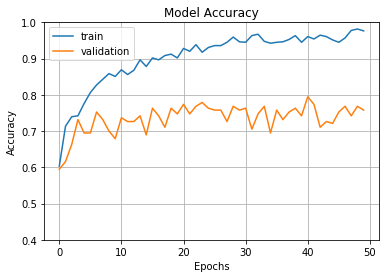

In [10]:
fig1 = plt.gcf()
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.axis(ymin=0.4,ymax=1)
plt.grid()
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend(['train', 'validation'])
plt.show()

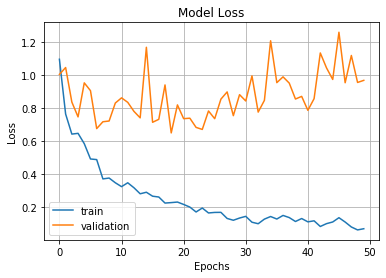

In [11]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.grid()
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(['train', 'validation'])
plt.show()

In [12]:
def predict(resnet_model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
    img_array = tf.expand_dims(img_array, 0)

    predictions = resnet_model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

1/1 [==============================] - 0s 337ms/step


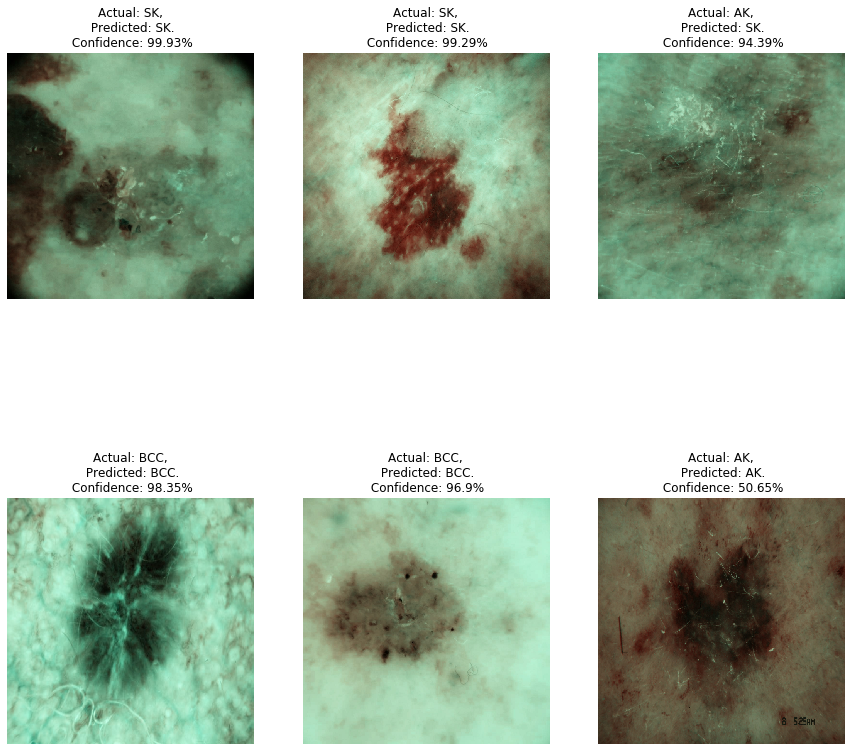

In [13]:
plt.figure(figsize=(15, 15))
for images, labels in val_ds.take(1):
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        predicted_class, confidence = predict(resnet_model, images[i].numpy())
        actual_class = class_names[labels[i]]

        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")

        plt.axis("off")

In [14]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

# Generate predictions for the test set
y_pred = []
y_true = []
for images, labels in val_ds:  # Iterate over all batches in test_ds
    predictions = resnet_model.predict(images)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

1/1 [==============================] - 10s 10s/step


In [15]:
#
report = classification_report(y_true, y_pred, target_names=class_names)
print("Classification Report:\n\n", report)



Classification Report:

               precision    recall  f1-score   support

          AK       0.76      0.74      0.75        57
         BCC       0.85      0.67      0.75        76
          SK       0.68      0.89      0.77        57

    accuracy                           0.76       190
   macro avg       0.76      0.77      0.76       190
weighted avg       0.77      0.76      0.76       190



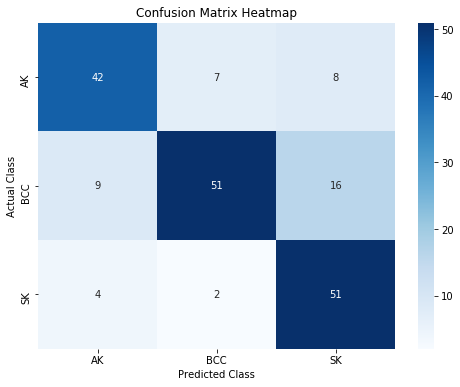

In [16]:
#

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Create a DataFrame from the confusion matrix
cm_df = pd.DataFrame(cm, columns=class_names, index=class_names)

# Generate heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix Heatmap")
plt.show()


In [20]:
!python3 --version

Python 3.5.2
